# Neural Blind Motion Deconvolution


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`observation`，shape `(1, 753, 668)`，dtype `<f4`：Real processed exposure luminance, dimensionless relative full scale; axes batch, row, column。未知量为753×668锐利亮度和51×51单位和运动核。

获取模型：803×718潜在padding亮度与未知非负核valid cross-correlation生成观测。

如何恢复：src.solvers.reconstruct：双无训练神经先验联合拟合2500步、MSE后SSIM。

GT与评价：GT来源于独立参考测量，不能与校准混用。

已有实验和图：cell7实测曝光；8主动GPU联合逆解；10独立曝光/上游/新图；11核/loss/前向残差；12指标与剖面。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留3个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。GT为RealBlur独立锐利相机曝光，有噪声/配准误差；不是合成真值；评估使用声明的平移规范与共同有效区域。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer both a sharp full-resolution luminance image and a 51 by 51 effective motion kernel from one real handheld exposure. The nonconvex bilinear inverse has an intrinsic image/kernel translation gauge and a trivial blurred-image/delta-kernel alternative.

Maintainer review of a full real-camera blind inverse problem. All fresh arrays below are computed with the local explicit model; archived measurements are separately identified.


Recover both a sharp normalized luminance image and an unknown 51-by-51 motion kernel from one measured handheld-camera exposure. The complete observation is 753-by-668 pixels; the optimization has 5,170,122 image/kernel generator parameters and executes all 2500 joint updates. Neither the scene nor the trajectory is supplied to the solver.

The reference-release method uses two untrained deep priors. The difficulty is a nonconvex bilinear acquisition model, a large overparameterized image prior, an unknown kernel and an intrinsic translation gauge. A delta kernel with the blurred image would fit the measurement but does not recover the independently observed scene. We therefore check real-reference image quality **and** unaligned image/kernel consistency.

The selected scientific comparison is independent short exposure, identity blurred observation, the exact bound observation reconstructed by the original numerical release, and a fresh local reconstruction. This is not a reproduction of historical Levin/Lai paper tables.


## 2. Data

The complete 753 by 668 RealBlur-J raster is normalized processed luminance, not linear sensor radiance. A separately acquired registered short exposure is evaluation truth for the processed-image task. It is never supplied to either untrained generator or their initialization.


The bound data are the **entire real photograph** `scene026/blur/blur_3.png` from RealBlur-J, captured with a Sony A7R3. The source is the official RealBlur archive on [Hugging Face](https://huggingface.co/datasets/rimchang/RealBlur). The dataset paper is Rim et al., *Real-World Blur Dataset for Learning and Benchmarking Deblurring Algorithms*, ECCV 2020. The source repository revision verified at acquisition is `4d65bb32daa6dd89fd629311a43e69c945e631e9`. The data license is CC BY 4.0, with full attribution/legal text in validation.

RealBlur-J is JPEG-domain intensity data distributed in PNG containers after dataset registration/intensity processing. Packaging converts the full RGB raster to integer YCrCb luminance and divides by 255; it introduces no resize, crop, synthetic blur or additional noise. The independent `scene026/gt/gt_3.png` exposure is maintainer-only truth for evaluating this processed imaging task. It is not a noiseless latent camera radiance field and is never given to the reconstruction algorithm.

Only an initial HTTP Range prefix of the official 13.1 GB archive was downloaded. All selected PNG members were fully decoded and individually hashed; this does **not** constitute a verified download/hash of the entire archive. The source PNG, complete member paths and cryptographic hashes are indexed privately and in validation.

| Public key | Shape | Dtype | Meaning and units |
|---|---|---|---|
| observation | (1,753,668) | float32 | Normalized measured luminance, dimensionless relative full scale; batch,row,column |

| Acquisition/model parameter | Value | Unit | Role |
|---|---|---|---|
| Complete distributed raster | 753 by 668 | pixel | No benchmark spatial crop or downsampling |
| Conversion | `(4899 R+9617 G+1868 B+8192)>>14`, then `/255` | DN to relative full scale | Full-range YCrCb luminance, not linear radiance |
| Quantization step | 1/255 | relative full scale | Distributed processed observation precision |
| Coordinate orientation | row down, column right | pixel | Same for observation, latent and output |
| Assumed kernel support | 51 by 51 | pixel | Finite-support inverse-model assumption, not known trajectory |
| Padded latent | 803 by 718 | pixel | 25 unknown boundary pixels on each side |
| Acquisition boundary | valid cross-correlation | none | No circular blur or measured-image padding |
| Noise variance/trajectory | unknown | none | No target-derived calibration is introduced |
| Exposure time/physical pixel pitch | not supplied | none | Not required for this normalized pixel-domain inverse problem |

The raw NPZ contains exactly the observation. True images, fitted kernels, network weights and synthetic object seeds are absent from the public input.

The bound observation is the complete `scene026/blur/blur_3.png` camera exposure from the RealBlur-J dataset, converted to the integer luminance channel of the full-range YCrCb convention, then divided by 255. It has not been resized, cropped, synthetically blurred or corrupted with additional noise. RealBlur-J is processed JPEG-domain data distributed in PNG containers. Dataset registration and intensity processing predate this task; this is not raw sensor radiance.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| `observation` | `(1, 753, 668)` | `float32` | Real processed exposure luminance, dimensionless relative full scale; axes batch, row, column |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Source modality | Sony A7R3 real camera exposure | none | Measured handheld motion blur, not a numerical blur simulation |
| Spatial sampling | 753 rows by 668 columns | pixel | Complete distributed image raster; row increases downward and column rightward |
| Photometric convention | Integer full-range YCrCb luminance divided by 255 | relative full scale | Quantized processed intensity; no linear-radiance claim |
| Luminance conversion | `(4899 R + 9617 G + 1868 B + 8192) >> 14` | integer DN | RGB channels have 8-bit range; divide the integer result by 255 |
| Quantization step | `1/255` | relative full scale | Precision of the distributed luminance observation |
| Assumed kernel support | 51 by 51 | pixel | Specified finite-support blind forward-model assumption, not a measured calibration |
| Latent model extent | 803 rows by 718 columns | pixel | Adds a 25-pixel latent boundary on each side to model the complete measurement |
| Forward boundary convention | Valid cross-correlation | none | No circular convolution; no observed boundary padding |
| Kernel origin convention | Index `(25,25)` corresponds to the reported image origin | pixel | Translation remains ambiguous within the specified gauge |
| Exposure trajectory and noise variance | Unknown | none | Must not be assumed calibrated; structured residuals may remain |
| Pixel pitch and exposure time | Not supplied with this sample | none | Neither is needed for the pixel-domain model; no metric displacement or radiometric inference is requested |


In [1]:
from pathlib import Path
import os, sys, json, time, subprocess
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
TASK=Path.cwd()
if not (TASK/'data/raw_data.npz').exists():
    TASK=TASK.parent
if not (TASK/'data/raw_data.npz').exists():
    raise RuntimeError('Run this notebook from its task or notebooks directory')
os.chdir(TASK)
sys.path.insert(0,str(TASK))
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import torch
from src.preprocessing import load_observation
from src.solvers import reconstruct
from src.visualization import image_metrics, forward_nrmse, align_translation, comparison_figure, diagnostic_figure
print('Task:',TASK.name,'Python executable:',sys.executable,'Torch:',torch.__version__,'GPU:',torch.cuda.get_device_name(0))

Task: neural_blind_motion_deconvolution Python executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe Torch: 2.9.1+cu128 GPU: NVIDIA GeForce RTX 4080 SUPER


## 3. Physics

The valid-correlation model below maps an 803 by 718 padded latent image and positive unit-sum kernel to the entire observation. The submitted central image and kernel are assessed together without alignment for forward consistency; only the declared integer translation gauge is removed in reference-image scoring.


Let $y$ be observed luminance, $u$ the padded sharp image, $k$ the unknown correlation kernel and $\epsilon$ measurement/model error. For image indices $r,c$ and kernel offsets $a,b$,


$$
y_{r,c}=\sum_{a=0}^{50}\sum_{b=0}^{50}k_{a,b}u_{r+a,c+b}+\epsilon_{r,c},\quad k\geq0,\quad\sum_{a,b}k_{a,b}=1.
$$


The complete 803-by-718 latent produces all 753-by-668 measurements by **valid** correlation. This is the neural optimization's actual forward domain. The submitted image is $x_{r,c}=u_{r+25,c+25}$. Correlating only $x$ with $k$ can explain the smaller 703-by-618 measurement region `observation[25:-25,25:-25]`; it must not borrow the hidden target to complete a border. Reflection padding occurs in feature convolutions, not in this acquisition model.

Translation is not identifiable: the correlation remains unchanged by simultaneous array-coordinate shifts $u_s(r)=u(r-s)$ and $k_s(a)=k(a-s)$, provided support is not truncated. In the physical convolution PSF convention, kernel reversal turns this into opposite image/PSF shifts. An independent discrete compact-support test verifies the sign rather than inferring it from the reconstruction.

Image/reference metrics therefore use one integer displacement in a fixed plus/minus-25 search box, chosen by demeaned cross-correlation with a row-major tie rule. A fixed 50-pixel interior excludes the 25-pixel model radius plus the maximum gauge displacement. It retains 370904 pixels including the sign and difficult background. The forward metric uses the original submitted image and kernel without that alignment, scaling, or padding.

NCC is uncentered cosine similarity. NRMSE is RMS image error divided by the independent reference interior's dynamic range. The forward NRMSE uses the observed valid region's dynamic range. The kernel must remain nonnegative with unit sum. The real exposure includes quantization, noise and possible nonuniform motion, so a fitted effective kernel is not a ground-truth trajectory.


## 4. Method

The local reference-release variant retains dual untrained priors, nonlocal image blocks, kernel softmax and all 2500 joint Adam updates. It uses MSE before iteration 500 and SSIM afterward, without the original paper's TV term. Deterministic backend settings and pre-final-update return convention are part of the reproduced method.


Write $u=G_\theta(z+\eta)$ and $k=H_\phi(v)$, where $G$ is the image generator, $H$ the kernel generator, $\theta,\phi$ their weights, and $z,v$ fixed random inputs. Image input shape is `(1,8,803,718)`, kernel input length 200; both are uniform on `[0,0.1)`. A new image perturbation $\eta$ has standard deviation 0.001 at every update. Kernel input is not perturbed. No paired training data or pretrained inverse weights are used.

The image prior has five 128-channel scales with 16-channel skips. Each encoder scale has stride-2 and stride-1 reflected 3-by-3 convolutions, batch normalization and slope-0.2 LeakyReLU. The final three scales additionally use dot-product nonlocal residuals. Their queries have 64 channels and keys/values are max-pooled; interaction weights are divided by the pooled location count, **not softmax-normalized**. Bilinear decoding with `align_corners=False` joins centered skip/deeper features, then applies 3-by-3 and 1-by-1 convolutions. Odd-sized branch crops are explicit. A sigmoid maps the final latent into `(0,1)`.

The kernel prior is a biased 200-to-1000-to-2601 network with ReLU6 and a final softmax, reshaped to 51-by-51. Positivity and unit sum follow from this parameterization. It is not recentered from target knowledge.

For zero-based iteration $t$, the prediction is $\widehat y=A_k u$. With $N=753\times668$ measurement pixels,


$$
\mathcal L_t=\begin{cases}N^{-1}\sum_{r,c}(\widehat y_{r,c}-y_{r,c})^2,&t<500,\\
1-\mathrm{SSIM}(\widehat y,y),&t\geq500.\end{cases}
$$


SSIM uses an 11-by-11 separable Gaussian window of standard deviation 1.5 pixels. Window-convolved means are $\mu_a,\mu_b$, variances are $v_a,v_b$ and covariance is $c$. All use zero-padded moments and population conventions. With $C_1=0.01^2$ and $C_2=0.03^2$,


$$
\mathrm{SSIM}(a,b)=\frac1N\sum_{r,c}
\frac{(2\mu_a\mu_b+C_1)(2c+C_2)}{(\mu_a^2+\mu_b^2+C_1)(v_a+v_b+C_2)}.
$$


Both parameter groups are updated jointly by Adam, with beta=(0.9,0.999), epsilon `1e-8`, no weight decay and no TV term. Initial image/kernel rates are 0.01/0.0001 and halve at iterations 1600,1900,2200. Moment state persists across the MSE-to-SSIM switch. All 2500 iterations execute; no best-target checkpoint, early stopping, kernel fitting from truth or extra nonblind solver is used. The returned arrays are the last forward tensors immediately before the final optimizer update, matching the original save convention.

This is the specified **reference-release variant** of the CVPR 2020 method: the release removed the paper's TV penalty and added the two-stage discrepancy/nonlocal blocks. These differences are disclosed rather than described as exact reproduction of the paper's original regularized equation. The paper's historical comparative experiment tables are not results for this new real observation.

For reproducibility, the final original oracle and cleaned method use the same fixed seed and full Torch deterministic algorithm mode, disabled TF32 and `CUBLAS_WORKSPACE_CONFIG=:4096:8`. CuDNN determinism alone left small reflection-padding backward differences that Adam amplified. That investigated historical run is archived separately. The full deterministic benchmark is substantially slower; the review allows 5400 seconds rather than replacing reconstruction with cached arrays.


## 5. Results

The preserved active GPU path computes both unknowns before loading independent upstream and short-exposure comparisons. Keep full image/kernel diagnostics, unaligned observation residual, gauge-aware reference scores and true optimization history; no cached reconstruction supplies a fresh curve.


The following archived array was produced by the original upstream implementation on this exact observation, under the final deterministic backend. It is a reproduced method result, not actual truth or a fresh cleaned reconstruction. The independently acquired short exposure is loaded separately for quality assessment. All reported scores are computed here from these identified arrays; historical paper numbers are not mixed into the table.

The pass boundaries were fixed from the earlier independent original run before cleaned full reconstruction. They are retained through the deterministic-backend correction and are not relaxed for the new output. Kernel correctness uses physical simplex constraints and coupled unaligned observation consistency because no independent true camera trajectory is available.


observation (1, 753, 668) float32 dimensionless luminance
Observed range: 0.003921568859368563 0.929411768913269


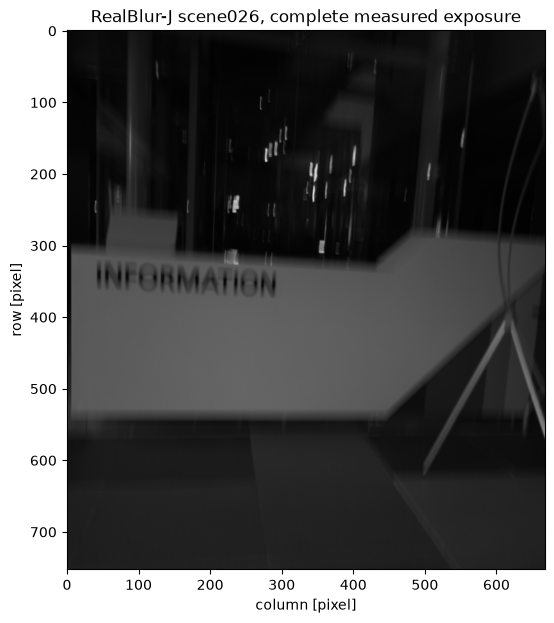

In [2]:
observation=load_observation('data/raw_data.npz')
with np.load('data/raw_data.npz',allow_pickle=False) as archive:
    for key in archive.files:
        print(key, archive[key].shape, archive[key].dtype, 'dimensionless luminance')
print('Observed range:',float(observation.min()),float(observation.max()))
fig,ax=plt.subplots(figsize=(7,7))
ax.imshow(observation,cmap='gray',vmin=0,vmax=1)
ax.set_title('RealBlur-J scene026, complete measured exposure')
ax.set_xlabel('column [pixel]');ax.set_ylabel('row [pixel]')
plt.show()

In [3]:
started=time.perf_counter()
fresh=reconstruct(observation,iterations=2500,seed=42,device='cuda',progress=False)
elapsed=time.perf_counter()-started
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh.reconstruction[None],kernel=fresh.kernel[None])
print(f'FRESH full 2500-step reconstruction completed: solver={fresh.runtime_seconds:.3f}s, cell={elapsed:.3f}s')
print('Image:',fresh.reconstruction.shape,fresh.reconstruction.dtype,'Kernel:',fresh.kernel.shape,fresh.kernel.dtype)
assert fresh.history.shape==(2500,4) and fresh.history[-1,0]==2499

FRESH full 2500-step reconstruction completed: solver=806.427s, cell=806.429s
Image: (753, 668) float32 Kernel: (51, 51) float32


In [4]:
with np.load('evaluation/ground_truth.npz',allow_pickle=False) as archive:
    truth=archive['reconstruction'][0]
with np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False) as archive:
    upstream=archive['reconstruction'][0]
    upstream_kernel=archive['kernel'][0]
    upstream_history=archive['history']
    upstream_prediction=archive['predicted'][0]
print('Original complete predicted-exposure RMS:',float(np.sqrt(np.mean((upstream_prediction-observation)**2))))
print('Original full history rows:',len(upstream_history),'last recorded objective:',float(upstream_history[-1,1]))
rows=[]
for label,image,kernel in [('Identity blurred input',observation,None),('Reproduced original method',upstream,upstream_kernel),('Fresh local 2500-step result',fresh.reconstruction,fresh.kernel)]:
    scores=image_metrics(image,truth)
    if kernel is not None:scores['forward_nrmse']=forward_nrmse(image,kernel,observation)
    rows.append({'measurement':label,**scores})
print(json.dumps(rows,indent=2))
completed=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
print('Judge exit:',completed.returncode)
report=json.loads(Path('output/judge_report.json').read_text())
print(json.dumps(report,indent=2))
assert completed.returncode==0 and report['passed'],report
np.testing.assert_allclose(fresh.reconstruction,upstream,rtol=2e-5,atol=2e-6)
np.testing.assert_allclose(fresh.kernel,upstream_kernel,rtol=2e-5,atol=2e-6)

Original complete predicted-exposure RMS: 0.007536552380770445
Original full history rows: 2500 last recorded objective: 0.005159854888916016


[
  {
    "measurement": "Identity blurred input",
    "ncc": 0.9816475547294945,
    "nrmse": 0.041142400423377426,
    "shift_row": 0,
    "shift_column": 0
  },
  {
    "measurement": "Reproduced original method",
    "ncc": 0.9918829592143033,
    "nrmse": 0.02933090843188145,
    "shift_row": -10,
    "shift_column": 15,
    "forward_nrmse": 0.008693088412780653
  },
  {
    "measurement": "Fresh local 2500-step result",
    "ncc": 0.9918829592143033,
    "nrmse": 0.02933090843188145,
    "shift_row": -10,
    "shift_column": 15,
    "forward_nrmse": 0.008693088412780653
  }
]


Judge exit: 0
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9918829592143033,
    "nrmse": 0.02933090843188145,
    "forward_nrmse": 0.008693088412780653,
    "kernel_mass_error": 1.338995616606553e-07,
    "kernel_negative_mass": 0.0,
    "image_min": 0.001306101679801941,
    "image_max": 0.9999985694885254,
    "shift_row": -10,
    "shift_column": 15
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.8926569351953423
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.03213680413900485
    },
    "forward_nrmse": {
      "comparison": "<=",
      "boundary": 0.00935309964438163
    },
    "kernel_mass_error": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "kernel_negative_mass": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "image_min": {
      "comparison": ">=",
      "boundary": 0.0
    },
    "image_max": {
      "comparison": "<=",
      "boundary": 1.0
    }
  },
  "errors": 

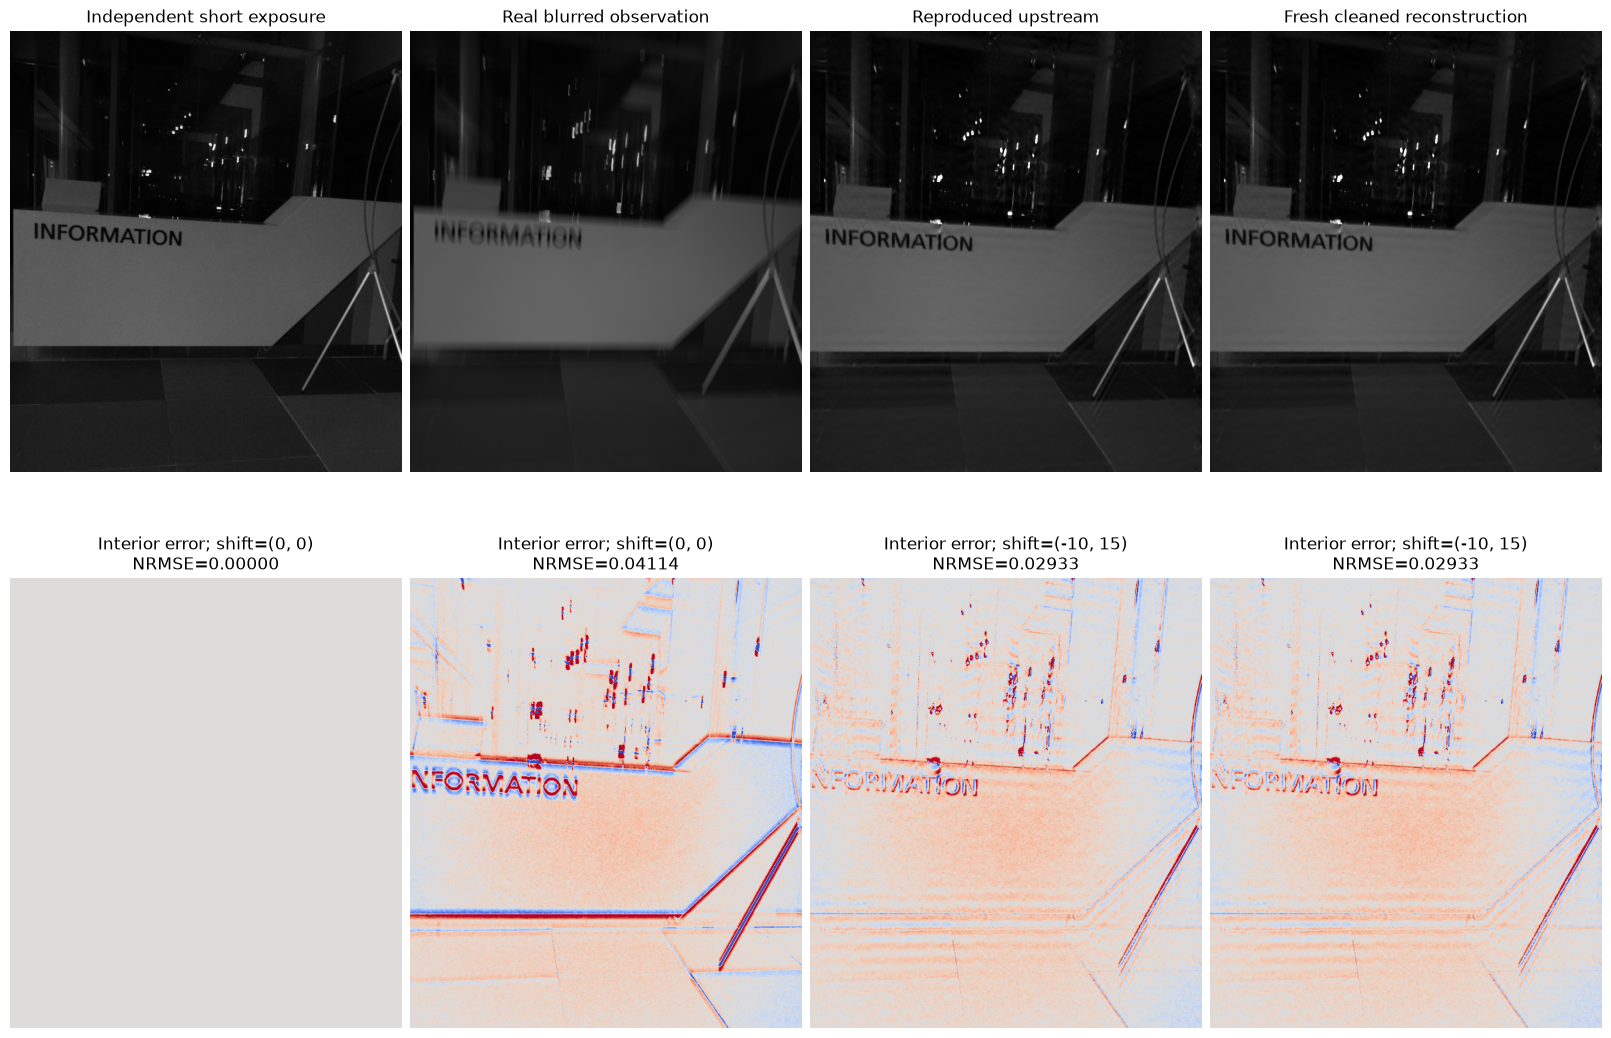

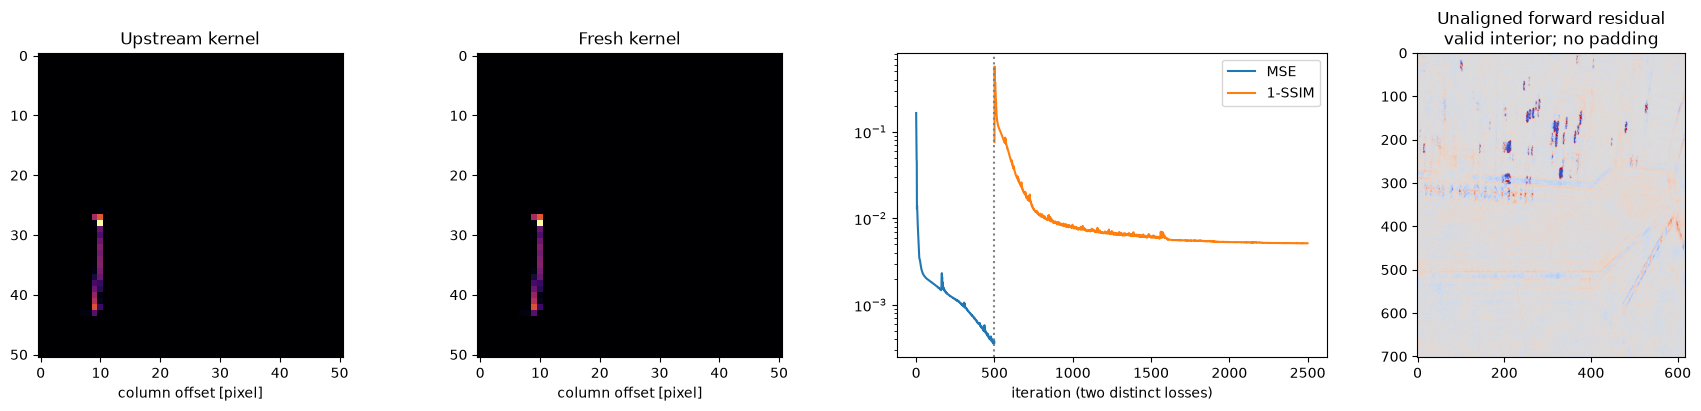

In [5]:
fig=comparison_figure(observation,truth,upstream,fresh.reconstruction)
plt.show()
fig=diagnostic_figure(fresh,upstream_kernel,observation)
plt.show()

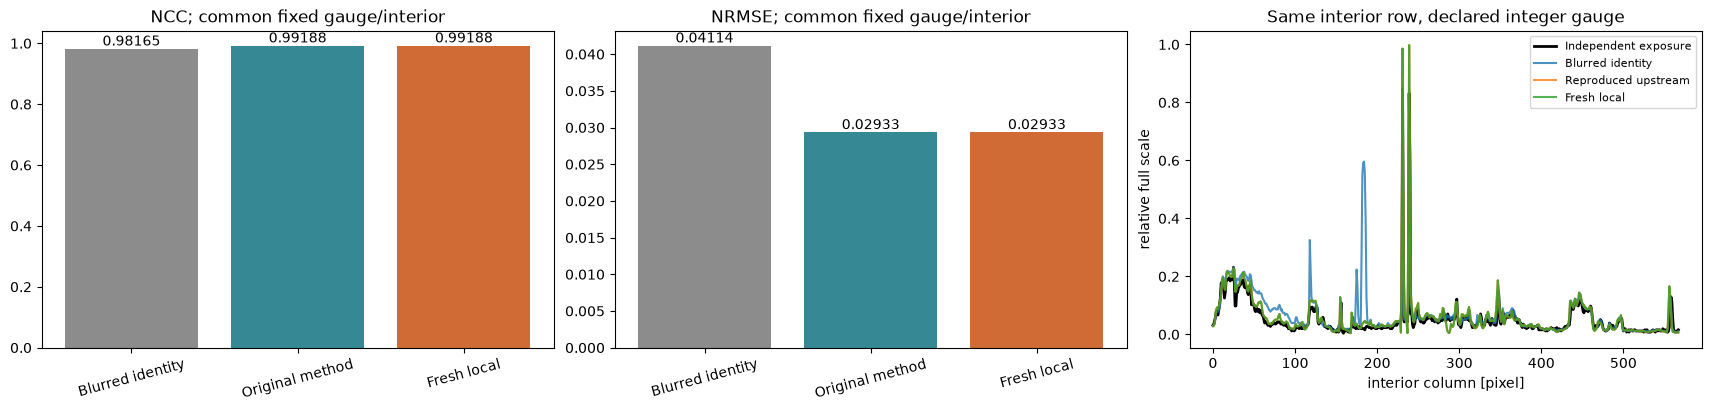

In [6]:
fig,axes=plt.subplots(1,3,figsize=(17,4),constrained_layout=True)
labels=['Blurred identity','Original method','Fresh local']
for ax,key in zip(axes[:2],['ncc','nrmse']):
    values=[row[key] for row in rows]
    ax.bar(labels,values,color=['#8c8c8c','#368895','#d16b35'])
    ax.set_title(key.upper()+'; common fixed gauge/interior')
    ax.tick_params(axis='x',rotation=15)
    for i,value in enumerate(values):ax.text(i,value,f'{value:.5f}',ha='center',va='bottom')
ref_profile=truth[50:-50,50:-50][200]
axes[2].plot(ref_profile,color='black',label='Independent exposure',linewidth=2)
for label,image in [('Blurred identity',observation),('Reproduced upstream',upstream),('Fresh local',fresh.reconstruction)]:
    aligned,_,shift=align_translation(image,truth)
    axes[2].plot(aligned[200],label=label,alpha=.8)
axes[2].set_title('Same interior row, declared integer gauge')
axes[2].set_xlabel('interior column [pixel]');axes[2].set_ylabel('relative full scale');axes[2].legend(fontsize=8)
plt.show()

In [7]:
improvement=1-rows[2]['nrmse']/rows[0]['nrmse']
print(f'Fresh NRMSE improvement over blurred input on the fixed evaluated region: {100*improvement:.2f}%')
print('Fresh kernel mass:',float(fresh.kernel.astype(np.float64).sum()),'negative mass:',float(np.maximum(-fresh.kernel,0).sum()))
print('Final conclusion uses only computed results; complete source/test/provenance gates are recorded in test/validation.md.')

Fresh NRMSE improvement over blurred input on the fixed evaluated region: 28.71%
Fresh kernel mass: 0.9999998661004383 negative mass: 0.0
Final conclusion uses only computed results; complete source/test/provenance gates are recorded in test/validation.md.


## 6. Conclusion

The recorded evidence supports one full-raster real-exposure benchmark with explicit coupled consistency. The effective kernel is not a true measured trajectory, and ringing, noise, nonuniform motion and processed-intensity modeling limit physical interpretation.


The active path reconstructs the full real observation with both unknowns, compares the newly computed output with an independently executed original algorithm, and evaluates it against an independently acquired short exposure. Passing the Judge alone is insufficient: upstream stage/full parity, acquisition adjoints, SSIM derivatives and blind-shift identities are checked separately in `test/`.

The fixed image metric removes only the intrinsic integer translation gauge; it never rescales intensities. The coupled forward metric does not align either array. This distinction prevents an unrelated fitted kernel from being hidden behind a visually sharp image.

Remaining artifacts should be interpreted as limitations of the selected reference-release prior and the uniform processed-intensity model: ringing/striped texture, noise and spatial variation may persist. The estimated kernel is an effective reconstruction quantity, not a validated true motion trace. This single real acquisition establishes a research-grade local benchmark instance, not general performance across RealBlur or replication of historical paper rankings.
